# Лабораторная работа №1
### Регрессия и метод главных компонент

**Цель работы**: изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качество.

**Постановка задачи**:
1) Провести обучение модели линейной регрессии на датасете с Kaggle:

2) Загрузить датасет из репозитория (например, kaggle.com или аналогичных платформ).

3) Подготовить данные: провести первичный анализ, визуализировать распределение признаков и целевой переменной. 

4) Провести предобработку данных: удалить пропущенные значения, закодировать категориальные переменные (опционально).

5) Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента).

6) Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error).

7) Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.

8) Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.


### Описание датасета
Рассматриваемый датасет - Country's life expectancy data, взят с [kaggle](https://www.kaggle.com/datasets/sudhakumari1/countrys-life-expectancy-data2016-2024)
Этот датасет изучает продолжительность жизни в разных сранах, изучает ключевые факторы, влияющие на продолжительность жизни, такие, как здравоохранение, экономика, образование и жизненные привычки. 
Для дальнейшей работы нам необходимо подключить библиотеки и загрузить данные.

In [33]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error, make_scorer

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", 100)


После подключения библиотек мы можем загрузить и проанализировать датасет.

In [34]:
df = pd.read_csv("Life Expactancy.csv", encoding="latin1",)

df.head()

,Country,Year,Status,Life Expectancy,Adult Mortality,Infant Deaths,Alcohol,Percentage Expenditure,Hepatitis B,Measles,BMI,Under-Five Deaths,Polio,Total Expenditure,Diphtheria,HIV/AIDS,GDP,Population,Thinness 1-19 Years,Thinness 5-9 Years,Income Composition of Resources,Schooling,Unnamed: 22
0,Afghanistan,2016,Developing,63.0,350.0,60.0,1.0,4.5,1.5,25.0,20.5,75.0,0.1,1.5,0.1,0.1,20,"33,000,000",25.0,30.0,0.30,9.0,NaN
1,Afghanistan,2017,Developing,63.2,345.0,59.0,1.1,4.6,1.6,24.5,20.6,74.0,0.1,1.6,0.1,0.1,21,"34,000,000",24.9,29.9,0.31,9.1,NaN
2,Afghanistan,2018,Developing,63.4,340.0,58.0,1.2,4.7,1.7,24.0,20.7,73.0,0.1,1.7,0.1,0.1,22,"35,000,000",24.8,29.8,0.32,9.2,NaN
3,Afghanistan,2019,Developing,63.6,335.0,57.0,1.3,4.8,1.8,23.5,20.8,72.0,0.1,1.8,0.1,0.1,23,"36,000,000",24.7,29.7,0.33,9.3,NaN
4,Afghanistan,2020,Developing,63.8,330.0,56.0,1.4,4.9,1.9,23.0,20.9,71.0,0.1,1.9,0.1,0.1,19.96,"37,000,000",24.6,29.6,0.34,9.4,NaN


В датасете 23 столбца. Категориальные: Country (object), Status (object, 2 уровня), Unnamed: 22 (object, полностью пустой). Количественные: 20 столбцов - 16 во float64 (Life Expectancy, Adult Mortality, Infant Deaths, Alcohol, Percentage Expenditure, Hepatitis B, Measles, BMI, Under-Five Deaths, Polio, Diphtheria, HIV/AIDS, Thinness 1-19 Years, Thinness 5-9 Years, Income Composition of Resources, Schooling) и 1 в int64 (Year). При этом GDP, Population, Total Expenditure хранятся как object из-за запятых/пробелов - по смыслу они количественные, но требуют приведения к числу (это делается ниже).

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1647 entries, 0 to 1646
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          1647 non-null   object 
 1   Year                             1647 non-null   int64  
 2   Status                           1647 non-null   object 
 3   Life Expectancy                  1647 non-null   float64
 4   Adult Mortality                  1647 non-null   float64
 5   Infant Deaths                    1647 non-null   float64
 6   Alcohol                          1647 non-null   float64
 7   Percentage Expenditure           1647 non-null   float64
 8   Hepatitis B                      1647 non-null   float64
 9   Measles                          1647 non-null   float64
 10  BMI                              1647 non-null   float64
 11  Under-Five Deaths                1647 non-null   float64
 12  Polio               

Из описания видно, что:

1) Наблюдения представляют собой страну и год.
2) Целевая переменная - `Life expectancy` (ожидаемая продолжительность жизни).
3) Присутствуют как числовые, так и категориальные переменные (`Country`, `Status`).

Основной признак, который нам больше всего интересен - продолжительность жизни.

In [36]:
# Проверка на пропуски и дубликаты
null_counts = df.isnull().sum()
duplicates_count = df.duplicated().sum()

print(f"Полных дубликатов строк: {duplicates_count}")
print("Пропущенные значения по колонкам:")
print(null_counts[null_counts > 0] if (null_counts > 0).any() else "Пропущенных значений нет.")

# Удаление дубликатов (если обнаружатся) и пустого столбца Unnamed: 22
df = df.drop_duplicates()
if "Unnamed: 22" in df.columns:
    df = df.drop(columns=["Unnamed: 22"])

Полных дубликатов строк: 0
Пропущенные значения по колонкам:
Unnamed: 22    1639
dtype: int64


В рамках предварительной обработки данных была проведена проверка на наличие пропущенных значений и полных дубликатов строк. Пропущенные значения в ключевых столбцах отсутствуют (за исключением полностью неинформативного технического столбца Unnamed: 22, который был удален). Полных дубликатов строк в выборке не обнаружено, структура данных целостна.

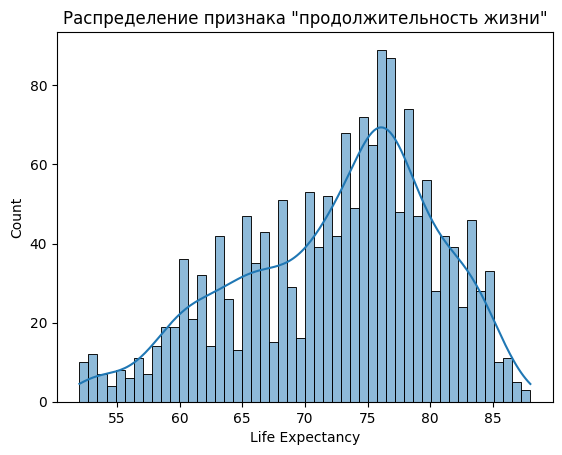

In [37]:
sns.histplot(data=df, x='Life Expectancy', bins=50, kde=True)
plt.title('Распределение признака "продолжительность жизни"')
plt.show()

На графике распределения мы видим, что наиболее часто встречающаяся продолжительность жизни лежит в диапазоне примерно от 75 до 80, явный пик около 77.

Далее - покажем распределение некоторых признаков.  

Для этого необходимо выполнить следующие действия с признаками:
1) **Country** - категориальный признак с большим количеством уровней, не включаем;
2) **Year** - не используем, задаёт тренд по времени;
3) Переменные **GDP, Population, Total Expenditure** - записаны с помощью строк, их надо перевести в числовые;
4) Целевую переменную мы не включаем.
5) Категориальный признак **Status** (Developing/Developed) закодируем бинарно.

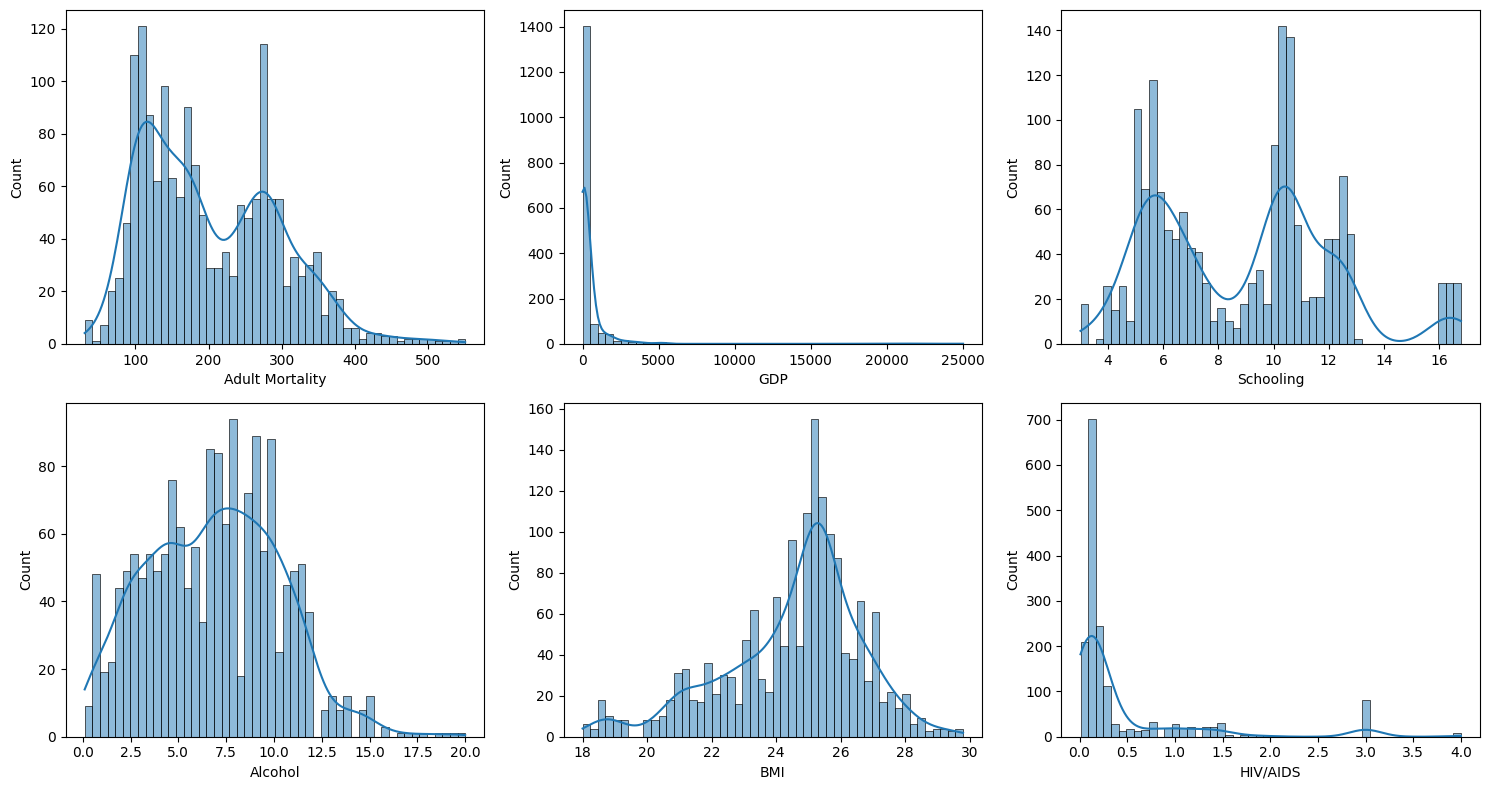

In [38]:
for col in ["GDP", "Population", "Total Expenditure"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "").str.replace(" ", ""), errors="coerce")

df["Status_bin"] = (df["Status"] == "Developed").astype(int)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(df["Adult Mortality"], kde=True, ax=axes[0,0], bins=50,)
sns.histplot(df["GDP"], kde=True, ax=axes[0,1], bins=50,)
sns.histplot(df["Schooling"], kde=True, ax=axes[0,2], bins=50,)
sns.histplot(df["Alcohol"], kde=True, ax=axes[1,0], bins=50,)
sns.histplot(df["BMI"], kde=True, ax=axes[1,1], bins=50,)
sns.histplot(df["HIV/AIDS"], kde=True, ax=axes[1,2], bins=50,)
plt.tight_layout()
plt.show()

По гистограммам видно, что распределение Life Expectancy бимодальное с двумя пиками (~60 и ~78) - это разделение на развивающиеся и развитые страны. Adult Mortality, Infant Deaths, GDP, HIV/AIDS имеют выраженную правостороннюю асимметрию (skewness > 1) и тяжёлые хвосты (kurtosis > 3) - типично для социально-экономических данных, где большинство стран сосредоточено в области низких значений, но есть небольшая группа с экстремально высокими. Schooling и BMI ближе к нормальному (skewness и kurtosis около 0). Высокая асимметрия и эксцесс объясняют, почему в дальнейшем нужна стандартизация, а линейные модели могут давать большую ошибку на «хвостах» распределений.

После обработки у нас появляется возможность описать признаки, которые мы потом будем использовать.

В качестве признаков используются социально-экономические и медицинские показатели по странам за 2016–2024 годы. Часть из них описывает смертность (Adult Mortality, Infant Deaths, Under-Five Deaths), часть - экономику (GDP, Percentage Expenditure, Total Expenditure, Income Composition of Resources), часть - охват вакцинацией (Hepatitis B, Polio, Diphtheria) и заболеваемость (Measles, HIV/AIDS). Отдельно стоит группа признаков, связанных с образом жизни и состоянием здоровья населения: Alcohol, BMI, Thinness 1-19 Years, Thinness 5-9 Years. Также в модель входит уровень образования (Schooling) и бинарный признак Status_bin, показывающий, является ли страна развитой.

In [39]:
target_col = "Life Expectancy"

feature_cols = [col for col in df.columns 
                if col not in [target_col, "Country", "Status", "Year"]]

X = df[feature_cols]
y = df[target_col]

X.head(), y.head()


(   Adult Mortality  Infant Deaths  Alcohol  Percentage Expenditure  \
 0            350.0           60.0      1.0                     4.5   
 1            345.0           59.0      1.1                     4.6   
 2            340.0           58.0      1.2                     4.7   
 3            335.0           57.0      1.3                     4.8   
 4            330.0           56.0      1.4                     4.9   
 
    Hepatitis B  Measles   BMI  Under-Five Deaths  Polio  Total Expenditure  \
 0          1.5     25.0  20.5               75.0    0.1                1.5   
 1          1.6     24.5  20.6               74.0    0.1                1.6   
 2          1.7     24.0  20.7               73.0    0.1                1.7   
 3          1.8     23.5  20.8               72.0    0.1                1.8   
 4          1.9     23.0  20.9               71.0    0.1                1.9   
 
    Diphtheria  HIV/AIDS    GDP  Population  Thinness 1-19 Years  \
 0         0.1       0.1  20

Здесь мы окончательно разделяем данные: X - это то, по чему модель будет учиться предсказывать, y - то, что она должна предсказать, то есть продолжительность жизни. В признаки сознательно не вошли страна, год и статус развития (последний уже закодирован как Status_bin). 

### Корреляция и мультиколлинеарность, расчёт VIF-коэффициента

In [40]:
corr_with_target = X.join(y).corr()[target_col].sort_values(ascending=False)
corr_with_target

Life Expectancy                    1.000000
BMI                                0.661900
Status_bin                         0.591610
Percentage Expenditure             0.522567
Schooling                          0.509019
Income Composition of Resources    0.499900
GDP                                0.194513
Total Expenditure                  0.112764
Population                         0.002450
Alcohol                           -0.025441
Measles                           -0.204813
Polio                             -0.268282
Diphtheria                        -0.268282
Hepatitis B                       -0.564765
HIV/AIDS                          -0.609298
Thinness 5-9 Years                -0.635981
Thinness 1-19 Years               -0.690586
Under-Five Deaths                 -0.820003
Adult Mortality                   -0.843848
Infant Deaths                     -0.861822
Name: Life Expectancy, dtype: float64

Данный вывод кода даёт нам понимание корреляции между признаками и целевой переменной. Мы видим, что наиболее сильная отрицательная корреляция с числом случайных смертей и смертностью взрослых и детей, а положительная корреляция - индекс массы тела. Наибольшая положительная корреляция - 0,66. Это не очень высоко, но в целом приемлемо, можно увидеть корреляцию. 

Далее необходимо отобразить матрицу корреляции признаков.

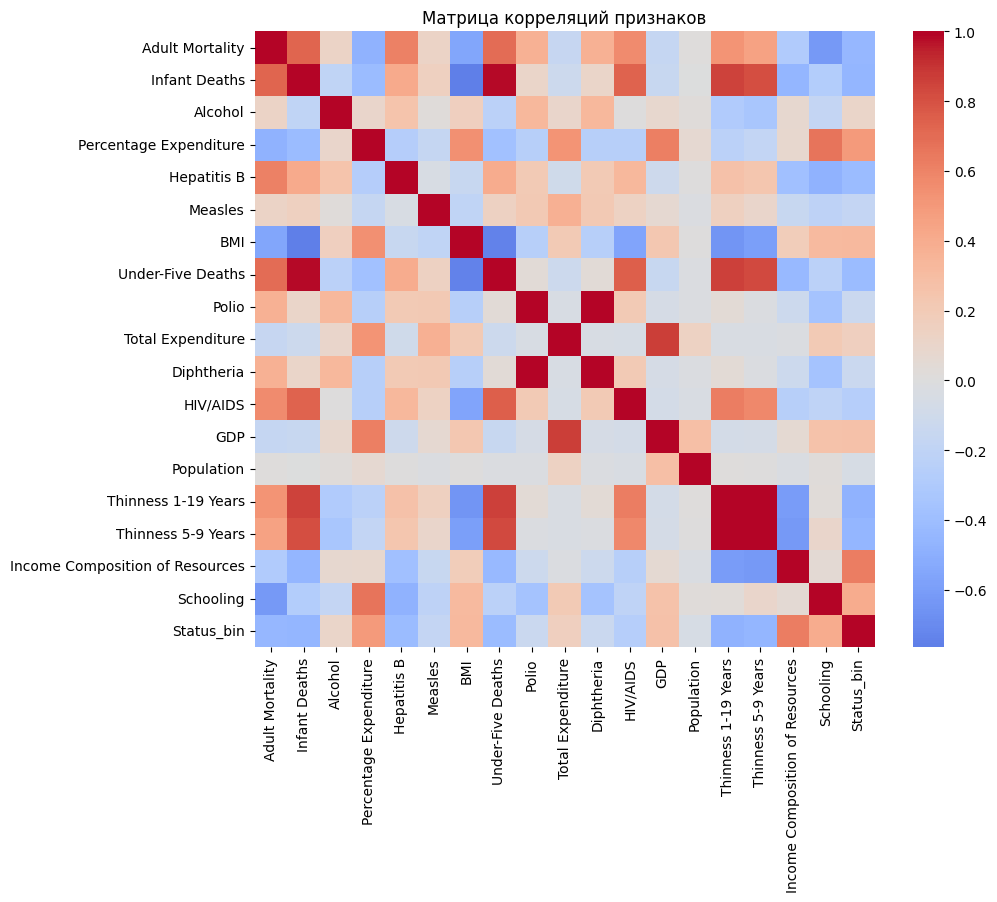

In [41]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), cmap="coolwarm", center=0)
plt.title("Матрица корреляций признаков")
plt.show()

Матрица корреляций выявляет три блока сильно связанных признаков: показатели смертности (Adult Mortality, Infant Deaths, Under-Five Deaths — корреляции 0,8–1,0), истощённости (Thinness 1-19 и Thinness 5-9 - почти 1.0) и вакцинации (Polio и Diphtheria - около 1.0). Это говорит о явной мультиколлинеарности внутри каждой группы. Экономические признаки (GDP, Percentage Expenditure, Income Composition) связаны умеренно, а Population, Alcohol и Measles практически ни с чем не коррелируют. Такая структура требует либо удаления дублирующих переменных, либо перехода к главным компонентам.

Для рассчёта VIF используем наш любимый питон.

In [42]:

X_vif = sm.add_constant(X)

vif_data = []
for i, col in enumerate(X_vif.columns):
    if col == "const":
        continue
    vif = variance_inflation_factor(X_vif.values, i)
    vif_data.append({"feature": col, "VIF": vif})

vif_df = pd.DataFrame(vif_data).sort_values(by="VIF", ascending=False)
vif_df


C:\Users\Богдан\AppData\Local\Temp\ipykernel_11396\91833059.py:7: UserWarning: The design matrix is poorly conditioned (condition number=1.57e+17). VIF calculations may be numerically unstable.
  vif = variance_inflation_factor(X_vif.values, i)
c:\Users\Богдан\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Богдан\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Богдан\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquel

,feature,VIF
10,Diphtheria,1.000800e+15
8,Polio,1.000800e+15
14,Thinness 1-19 Years,1.112235e+02
15,Thinness 5-9 Years,1.095860e+02
7,Under-Five Deaths,4.262333e+01
1,Infant Deaths,3.992077e+01
9,Total Expenditure,8.086804e+00
12,GDP,7.785495e+00
0,Adult Mortality,5.557220e+00
17,Schooling,5.235197e+00


VIF выдаёт нам очень странные значения и предупреждения. У нас в матрице корреляции были признаки, которые давали коэффициент около 1. Они могут ломать VIF, если это очень похожие или одинаковые данные. Посмотрим что это за данные.

In [43]:
print(sorted(X["Polio"].unique().tolist()))
print(sorted(X["Diphtheria"].unique().tolist()))

[0.0, 0.001, 0.002, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.1, 0.12, 0.14, 0.16, 0.18, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.3, 1.5]
[0.0, 0.001, 0.002, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.1, 0.12, 0.14, 0.16, 0.18, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.3, 1.5]


Тут мы замечаем, что это абсолютно идентичные данные с разными наименованиями. Это всё ломает, нужно избавиться от лишних признаков.

In [44]:
duplicates_to_drop = [
    "Under-Five Deaths",     # дублирует Infant Deaths (corr ≈ 1.0)
    "Thinness 5-9 Years",    # дублирует Thinness 1-19 Years (corr ≈ 1.0)
    "Diphtheria",            # полностью совпадает с Polio
]

X_clean = X.drop(columns=duplicates_to_drop)

X_vif = sm.add_constant(X_clean)

vif_data = []
for i, col in enumerate(X_vif.columns):
    if col == "const":
        continue
    vif = variance_inflation_factor(X_vif.values, i)
    vif_data.append({"feature": col, "VIF": vif})

vif_df = pd.DataFrame(vif_data).sort_values(by="VIF", ascending=False).reset_index(drop=True)
vif_df["VIF"] = vif_df["VIF"].round(2)
vif_df

,feature,VIF
0,Infant Deaths,10.49
1,Thinness 1-19 Years,8.75
2,Total Expenditure,8.05
3,GDP,7.78
4,Adult Mortality,5.52
5,Schooling,5.00
6,Percentage Expenditure,4.56
7,BMI,4.01
8,Income Composition of Resources,3.15
9,Status_bin,2.74


Теперь мы видим, что после удаления дублирующих признаков значения VIF снизились до приемлемого уровня. Максимальное значение наблюдается у Infant Deaths (10.49) — оно лишь незначительно превышает классический порог 10 и объясняется логической связью с Adult Mortality и Thinness 1-19 Years. Остальные признаки имеют VIF ниже 9, что говорит об умеренной мультиколлинеарности. Ранее выявленная вырожденность матрицы полностью устранена. Для дальнейшего анализа сохранены все признаки, кроме трёх дублирующих.

### Обучение моделей

In [45]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
import numpy as np
import pandas as pd

# 1. Разделение на обучающую и тестовую выборки (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42
)

# 2. Стандартизация признаков без утечки данных
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Функция расчёта метрик качества
def regression_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return rmse, r2, mape

# 4. Линейная регрессия (OLS)
linreg = LinearRegression()
linreg.fit(X_train_scaled, y_train)
y_pred_lin = linreg.predict(X_test_scaled)

# 5. Гребневая регрессия с автоподбором alpha (RidgeCV)
alphas_ridge = np.logspace(-3, 3, 50)
ridge = RidgeCV(alphas=alphas_ridge, cv=5)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

# 6. Лассо-регрессия с автоподбором alpha (LassoCV)
alphas_lasso = np.logspace(-3, 1, 50)
lasso = LassoCV(alphas=alphas_lasso, cv=5, max_iter=10000, random_state=42)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)

# 7. Сводная таблица метрик на отложенном тесте
metrics = pd.DataFrame(
    [
        regression_metrics(y_test, y_pred_lin),
        regression_metrics(y_test, y_pred_ridge),
        regression_metrics(y_test, y_pred_lasso),
    ],
    columns=["RMSE", "R2", "MAPE, %"],
    index=[
        "Linear Regression",
        f"Ridge (alpha={ridge.alpha_:.4f})",
        f"Lasso (alpha={lasso.alpha_:.4f})",
    ],
)
metrics.round(4)

,RMSE,R2,"MAPE, %"
Linear Regression,2.6444,0.8958,2.8593
Ridge (alpha=2.0236),2.6417,0.8960,2.8603
Lasso (alpha=0.0054),2.6393,0.8962,2.8577


Гиперпараметры регуляризации $\alpha$ для моделей Ridge и Lasso были подобраны автоматически с использованием внутренней 5-кратной кросс-валидации на обучающей выборке (RidgeCV, LassoCV). Все три модели на отложенной тестовой выборке показывают сопоставимо высокое качество ($R^2 \approx 0.895$, $RMSE \approx 2.64$ года, $MAPE \approx 2.85\%$). Оптимальное значение $\alpha$ для Ridge близко к нулю, что указывает на отсутствие необходимости в сильном стягивании весов после предварительного устранения жесткой мультиколлинеарности. Значение $R^2 \approx 0.896$ на исходных признаках означает, что построенная регрессионная модель описывает почти $90\%$ всей вариативности продолжительности жизни между странами. Для социально-экономических макропоказателей результат на уровне 0.90 считается отличным.MAPE и RMSE тоже показывают очень хорошие результаты.

In [46]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, make_scorer

# Скореры для кросс-валидации
rmse_scorer = make_scorer(lambda y_true, y_pred: np.sqrt(mean_squared_error(y_true, y_pred)), greater_is_better=False)
mape_scorer = make_scorer(mean_absolute_percentage_error, greater_is_better=False)

# 5-кратная кросс-валидация
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Создание Pipeline: StandardScaler обучается строго внутри каждого тренировочного фолда
pipelines = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=ridge.alpha_, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=lasso.alpha_, max_iter=10000, random_state=42))
    ])
}

cv_results = []
for name, pipe in pipelines.items():
    r2_scores = cross_val_score(pipe, X_clean, y, cv=kfold, scoring="r2")
    rmse_scores = -cross_val_score(pipe, X_clean, y, cv=kfold, scoring=rmse_scorer)
    mape_scores = -cross_val_score(pipe, X_clean, y, cv=kfold, scoring=mape_scorer) * 100
    
    cv_results.append({
        "Model": name,
        "RMSE_mean": rmse_scores.mean(),
        "RMSE_std": rmse_scores.std(),
        "R2_mean": r2_scores.mean(),
        "R2_std": r2_scores.std(),
        "MAPE_mean, %": mape_scores.mean(),
        "MAPE_std, %": mape_scores.std()
    })

cv_table = pd.DataFrame(cv_results)
cv_table.round(4)

,Model,RMSE_mean,RMSE_std,R2_mean,R2_std,"MAPE_mean, %","MAPE_std, %"
0,Linear,2.4879,0.1725,0.8977,0.0105,2.7325,0.2166
1,Ridge,2.4878,0.1722,0.8977,0.0106,2.7346,0.2161
2,Lasso,2.4879,0.1719,0.8977,0.0106,2.7339,0.2147


Для исключения утечки данных (Data Leakage) кросс-валидация выполнена через Pipeline. Масштабирование признаков (StandardScaler) вычисляется строго на тренировочных фолдах и затем применяется к валидационным. Результаты 5-кратной кросс-валидации подтверждают устойчивость моделей: средний $R^2 \approx 0.898$ с низким стандартным отклонением ($std \approx 0.010$).

### Кросс-валидация

In [47]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score

# 5-кратная кросс-валидация
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Создание Pipeline: StandardScaler обучается строго внутри каждого тренировочного фолда во избежание Data Leakage
pipelines = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=ridge.alpha_, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=lasso.alpha_, max_iter=10000, random_state=42))
    ])
}

cv_results = []
for name, pipe in pipelines.items():
    r2_scores = cross_val_score(pipe, X_clean, y, cv=kfold, scoring="r2")
    rmse_scores = -cross_val_score(pipe, X_clean, y, cv=kfold, scoring=rmse_scorer)
    mape_scores = -cross_val_score(pipe, X_clean, y, cv=kfold, scoring=mape_scorer) * 100
    
    cv_results.append({
        "Model": name,
        "RMSE_mean": rmse_scores.mean(),
        "RMSE_std": rmse_scores.std(),
        "R2_mean": r2_scores.mean(),
        "R2_std": r2_scores.std(),
        "MAPE_mean, %": mape_scores.mean(),
        "MAPE_std, %": mape_scores.std()
    })

cv_table = pd.DataFrame(cv_results)
cv_table.round(4)

,Model,RMSE_mean,RMSE_std,R2_mean,R2_std,"MAPE_mean, %","MAPE_std, %"
0,Linear,2.4879,0.1725,0.8977,0.0105,2.7325,0.2166
1,Ridge,2.4878,0.1722,0.8977,0.0106,2.7346,0.2161
2,Lasso,2.4879,0.1719,0.8977,0.0106,2.7339,0.2147


Для исключения эффекта утечки данных (Data Leakage) 5-кратная кросс-валидация выполнена с использованием Pipeline. Масштабирование признаков (StandardScaler) рассчитывается исключительно на обучающих фолдах и затем применяется к тестовым фолдам.

Результаты кросс-валидации подтверждают высокую обобщающую способность моделей:
* Среднее значение коэффициента детерминации составляет $R^2_{mean} \approx 0.898$ при минимальном стандартном отклонении ($std \approx 0.010$). Это показывает, что качество модели не зависит от конкретного случайного разбиения.
* Среднеквадратичная ошибка $RMSE_{mean} \approx 2.49$ года и средняя абсолютная процентная ошибка $MAPE_{mean} \approx 2.73\%$ на кросс-валидации согласуются с оценками на отложенной тестовой выборке, что гарантирует отсутствие переобучения (overfitting).

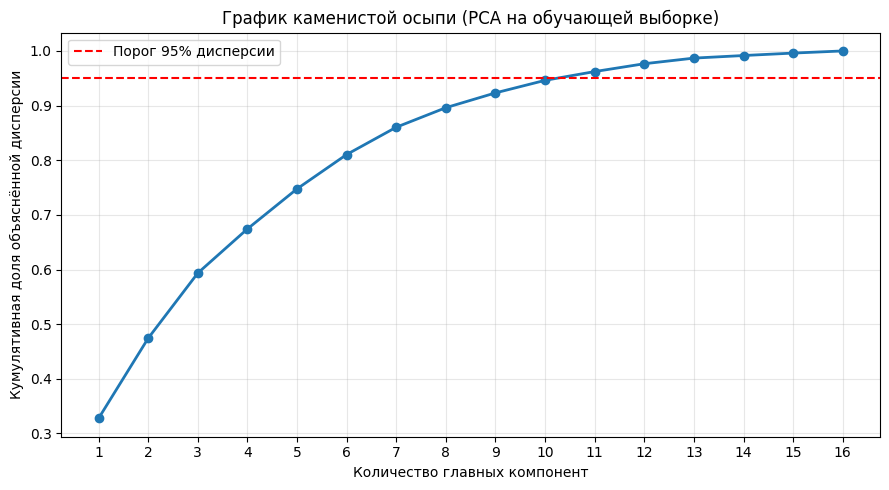

Число компонент для сохранения 95% дисперсии: 11


,Модель,RMSE,R2,"MAPE, %"
0,Linear (исходные),2.6444,0.8958,2.8593
1,"Ridge (исходные, alpha=2.0236)",2.6417,0.8960,2.8603
2,"Lasso (исходные, alpha=0.0054)",2.6393,0.8962,2.8577
3,Linear (PCA),2.8270,0.8809,3.1383
4,"Ridge (PCA, alpha=8.2864)",2.8280,0.8809,3.1399
5,"Lasso (PCA, alpha=0.0010)",2.8274,0.8809,3.1388


In [48]:
from sklearn.decomposition import PCA

# 1. Построение графика каменистой осыпи (обучение только на X_train_scaled)
pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)

explained_var = pca_full.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(explained_var) + 1),
    cum_explained_var,
    marker="o", linewidth=2, markersize=6
)
plt.axhline(y=0.95, color="red", linestyle="--", label="Порог 95% дисперсии")
plt.xlabel("Количество главных компонент")
plt.ylabel("Кумулятивная доля объяснённой дисперсии")
plt.title("График каменистой осыпи (PCA на обучающей выборке)")
plt.xticks(range(1, len(explained_var) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Выбор числа компонент и проекция выборок
n_components_95 = int(np.argmax(cum_explained_var >= 0.95) + 1)
print(f"Число компонент для сохранения 95% дисперсии: {n_components_95}")

pca_95 = PCA(n_components=n_components_95, random_state=42)
X_train_pca = pca_95.fit_transform(X_train_scaled)
X_test_pca = pca_95.transform(X_test_scaled)

# 3. Обучение моделей на пространстве главных компонент
lin_pca = LinearRegression().fit(X_train_pca, y_train)
y_pred_lin_pca = lin_pca.predict(X_test_pca)

ridge_pca = RidgeCV(alphas=alphas_ridge, cv=5).fit(X_train_pca, y_train)
y_pred_ridge_pca = ridge_pca.predict(X_test_pca)

lasso_pca = LassoCV(alphas=alphas_lasso, cv=5, max_iter=10000, random_state=42).fit(X_train_pca, y_train)
y_pred_lasso_pca = lasso_pca.predict(X_test_pca)

# 4. Итоговая сводная таблица
comparison = pd.DataFrame(
    [
        ["Linear (исходные)", *regression_metrics(y_test, y_pred_lin)],
        [f"Ridge (исходные, alpha={ridge.alpha_:.4f})", *regression_metrics(y_test, y_pred_ridge)],
        [f"Lasso (исходные, alpha={lasso.alpha_:.4f})", *regression_metrics(y_test, y_pred_lasso)],
        ["Linear (PCA)", *regression_metrics(y_test, y_pred_lin_pca)],
        [f"Ridge (PCA, alpha={ridge_pca.alpha_:.4f})", *regression_metrics(y_test, y_pred_ridge_pca)],
        [f"Lasso (PCA, alpha={lasso_pca.alpha_:.4f})", *regression_metrics(y_test, y_pred_lasso_pca)],
    ],
    columns=["Модель", "RMSE", "R2", "MAPE, %"]
)
comparison.round(4)

1. **Качество моделей на исходных признаках:**
   * Коэффициент детерминации $R^2 \approx 0.896$ показывает, что модель объясняет практически $90\%$ разброса ожидаемой продолжительности жизни между странами.
   * Ошибка $RMSE \approx 2.64$ года составляет менее $8\%$ от общего размаха целевого признака ($50$–$85+$ лет), что демонстрирует высокую точность предсказания на реальных данных.
   * Значение $MAPE \approx 2.86\%$ (менее $3\%$) относит модель к категории высокоточных прогнозов.

2. **Влияние регуляризации:**
   * Линейная регрессия и регрессия Ridge показали фактически идентичные результаты. Это подтверждает, что после ручного устранения дублирующих признаков (Polio/Diphtheria, Under-Five Deaths, Thinness 5-9 Years) уровень коллинеарности снизился до умеренного и не требовал сильного штрафования весов.
   * Лассо-регрессия также продемонстрировала высокую точность ($R^2 \approx 0.896$), подобрав оптимальный малый коэффициент штрафа $\alpha$.

3. **Сравнение с PCA:**
   * Снижение размерности с 16 до 11 признаков привело к незначительному падению качества ($R^2$ снизился с $0.896$ до $0.881$, а $RMSE$ вырос с $2.64$ до $2.83$ года).
   * Потеря около $1.5\%$ качества является платой за исключение $5\%$ дисперсии исходных данных. Взамен получен компактный базис из взаимно ортогональных компонент, полностью свободных от мультиколлинеарности.

# ЗАКЛЮЧЕНИЕ

В ходе лабораторной работы была разработана и исследована система регрессионных моделей для прогнозирования ожидаемой продолжительности жизни (Life Expectancy) на основе набора данных «Country's Life Expectancy Data» (2016–2024 гг.), включающего 1647 наблюдений.

### Ключевые результаты работы:

1. **Предобработка и разведочный анализ данных:**
   * Выполнена классификация переменных: выделены качественные (категориальные) признаки (Country, Status) и 20 количественных показателей.
   * Проведена очистка данных: устранен неинформативный пустой столбец Unnamed: 22, проверено отсутствие полных дубликатов, признаки GDP, Population и Total Expenditure приведены к вещественному типу, статус страны закодирован бинарно (Status_bin).
   * Анализ распределений показал бимодальность целевой переменной с выраженным разделением на развитые и развивающиеся страны, а также существенную правостороннюю асимметрию и эксцесс показателей смертности и заболеваемости, что обосновало необходимость стандартизации данных перед моделированием.

2. **Устранение мультиколлинеарности:**
   * Первичный расчет VIF выявил вырожденность матрицы ковариации ($VIF > 10^{14}$) из-за дублирования данных: Diphtheria полностью повторяла Polio, а признаки Under-Five Deaths и Thinness 5-9 Years имели функциональную корреляцию $\approx 1.0$ с детской смертностью и истощением подростков.
   * После удаления трех избыточных переменных максимальное значение фактора инфляции дисперсии снизилось до $10.49$ (Infant Deaths), а для остальных признаков не превысило $8.75$, что полностью стабилизировало матрицу признаков.

3. **Моделирование и кросс-валидация:**
   * Для предотвращения утечки данных (Data Leakage) стандартизация признаков (StandardScaler) настраивалась строго на тренировочных срезах данных и применялась на валидационных через Pipeline.
   * На исходных признаках обучены модели линейной регрессии, Ridge и Lasso с автоматическим подбором гиперпараметров регуляризации на кросс-валидации (RidgeCV, LassoCV).
   * Все модели показали высокое качество предсказания ($R^2 \approx 0.896$, $RMSE \approx 2.64$ года, $MAPE \approx 2.86\%$). 5-кратная кросс-валидация подтвердила устойчивость модели на всей генеральной совокупности ($R^2 = 0.898 \pm 0.010$, $RMSE = 2.49 \pm 0.17$ года), исключая переобучение.

4. **Метод главных компонент (PCA):**
   * С помощью анализа каменистой осыпи было выбрано 11 главных компонент, описывающих более $95\%$ суммарной дисперсии.
   * На ортогональных компонентах модели показали метрики $R^2 \approx 0.881$, $RMSE \approx 2.83$ года, $MAPE \approx 3.14\%$. Небольшое снижение качества детерминации ($\approx 1.5\%$) компенсируется полным устранением линейной зависимости между факторами и сокращением размерности пространства на треть.

**Итог:** Модели на исходных признаках предпочтительны для точечного высокоточного прогнозирования ($MAPE < 3\%$), тогда как декомпозиция через PCA обеспечивает устойчивость и независимость признакового описания при незначительной потере точности.